In [30]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from reportlab.lib.pagesizes import letter
from reportlab.pdfgen import canvas
import math
import os

# --- Configuration ---
input_image_path = '/Users/sophial/Downloads/poster.png'  # Replace with your image path
output_pdf_path = '/Users/sophial/Downloads/output.pdf'
tiling_mode = 'horizontal'  # Options: 'horizontal' or 'vertical'

# Letter size in points (1 pt = 1/72 inch)
page_width_pt, page_height_pt = letter

In [31]:
# --- Load image and read DPI ---
image = Image.open(input_image_path)
img_width, img_height = image.size
print(image.size)
dpi = int(image.info.get('dpi', (72, 72))[0])  # Default to 72 DPI if not available, assumes same dpi for x and y
print(dpi)
# Letter size in pixels at given DPI
letter_width_in, letter_height_in = 8.5, 11
page_width_px = int(letter_width_in * dpi)
page_height_px = int(letter_height_in * dpi)

# --- Calculate tiles ---
cols = math.ceil(img_width / page_width_px)
rows = math.ceil(img_height / page_height_px)

print(f"Image size: {img_width}x{img_height} pixels")
print(f"Will be tiled into {cols} columns x {rows} rows")

(10500, 6300)
350
Image size: 10500x6300 pixels
Will be tiled into 4 columns x 2 rows


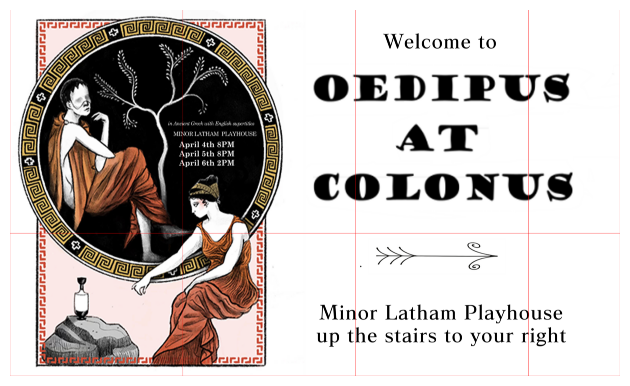

In [33]:
# --- Draw tile layout directly on image copy ---
preview_img = image.copy()
draw = ImageDraw.Draw(preview_img)
for row in range(rows):
    for col in range(cols):
        x0 = col * page_width_px
        y0 = row * page_height_px
        x1 = min(x0 + page_width_px, img_width)
        y1 = min(y0 + page_height_px, img_height)
        draw.rectangle([x0, y0, x1, y1], outline="red", width=3)

# Show preview image with red boxes
plt.imshow(preview_img)
plt.axis('off')
plt.tight_layout()
plt.show()

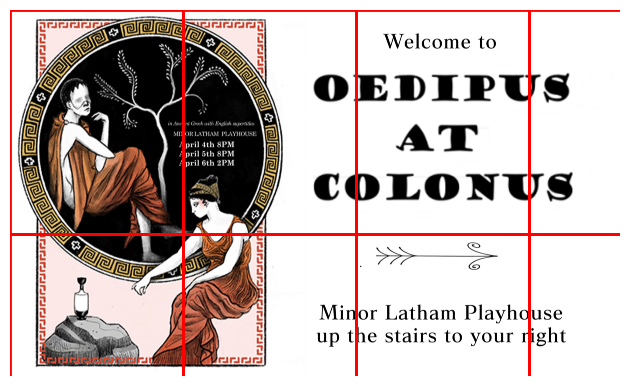

In [28]:
# --- Plot tile layout ---
fig, ax = plt.subplots()
ax.imshow(image)
for row in range(rows):
    for col in range(cols):
        x = col * page_width_px
        y = row * page_height_px
        rect = patches.Rectangle((x, y), page_width_px, page_height_px,
                                 linewidth=2, edgecolor='red', facecolor='none')
        ax.add_patch(rect)
# ax.set_xlim([0, img_width])
# ax.set_ylim([img_height, 0])  # Invert y-axis to match image coordinates
plt.axis('off')
plt.tight_layout()
plt.show()


In [34]:

# --- Create PDF with tiles ---
c = canvas.Canvas(output_pdf_path, pagesize=letter)

for row in range(rows):
    for col in range(cols):
        left = col * page_width_px
        upper = row * page_height_px
        right = min(left + page_width_px, img_width)
        lower = min(upper + page_height_px, img_height)

        box = (left, upper, right, lower)
        tile = image.crop(box)

        # Save to temporary file
        tile_path = f'tile_temp.png'
        tile.save(tile_path, dpi=(dpi, dpi))

        # Draw on PDF
        c.drawImage(tile_path, 0, 0, width=letter[0], height=letter[1])
        c.showPage()

        os.remove(tile_path)

c.save()
print(f"PDF saved to {output_pdf_path}")

PDF saved to /Users/sophial/Downloads/output.pdf
